In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv


# Assignmnet 02: Processing and viualizing The dataset "Telco-Customer-Churn"
`registration number : 22400879`

In this notebook we will processing the dataset we and finaly visualisation with interpreting that vizualization. This dataset is about who sto using the service of telcommuincation company. It is classification problem to analyze

In [4]:
# First let us load our data set 
data=pd.read_csv("/kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [5]:
# before processiong let see what we have in the dataset using functions like head tail and info
data.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [6]:
data.tail()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


In [8]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


The output of the the info function tell us there is no missing value in any column which that is good

In [12]:
# How many men and how many women and if there other
data.gender.value_counts()

gender
Male      3555
Female    3488
Name: count, dtype: int64

## Data processiong of the dataset

In [14]:
data['Churn'] = data['Churn'].map({'Yes': 1, 'No': 0})

In [15]:
# check if the changing happen 
print(data['Churn'].value_counts())

Churn
0    5174
1    1869
Name: count, dtype: int64


### Demographic Analysis


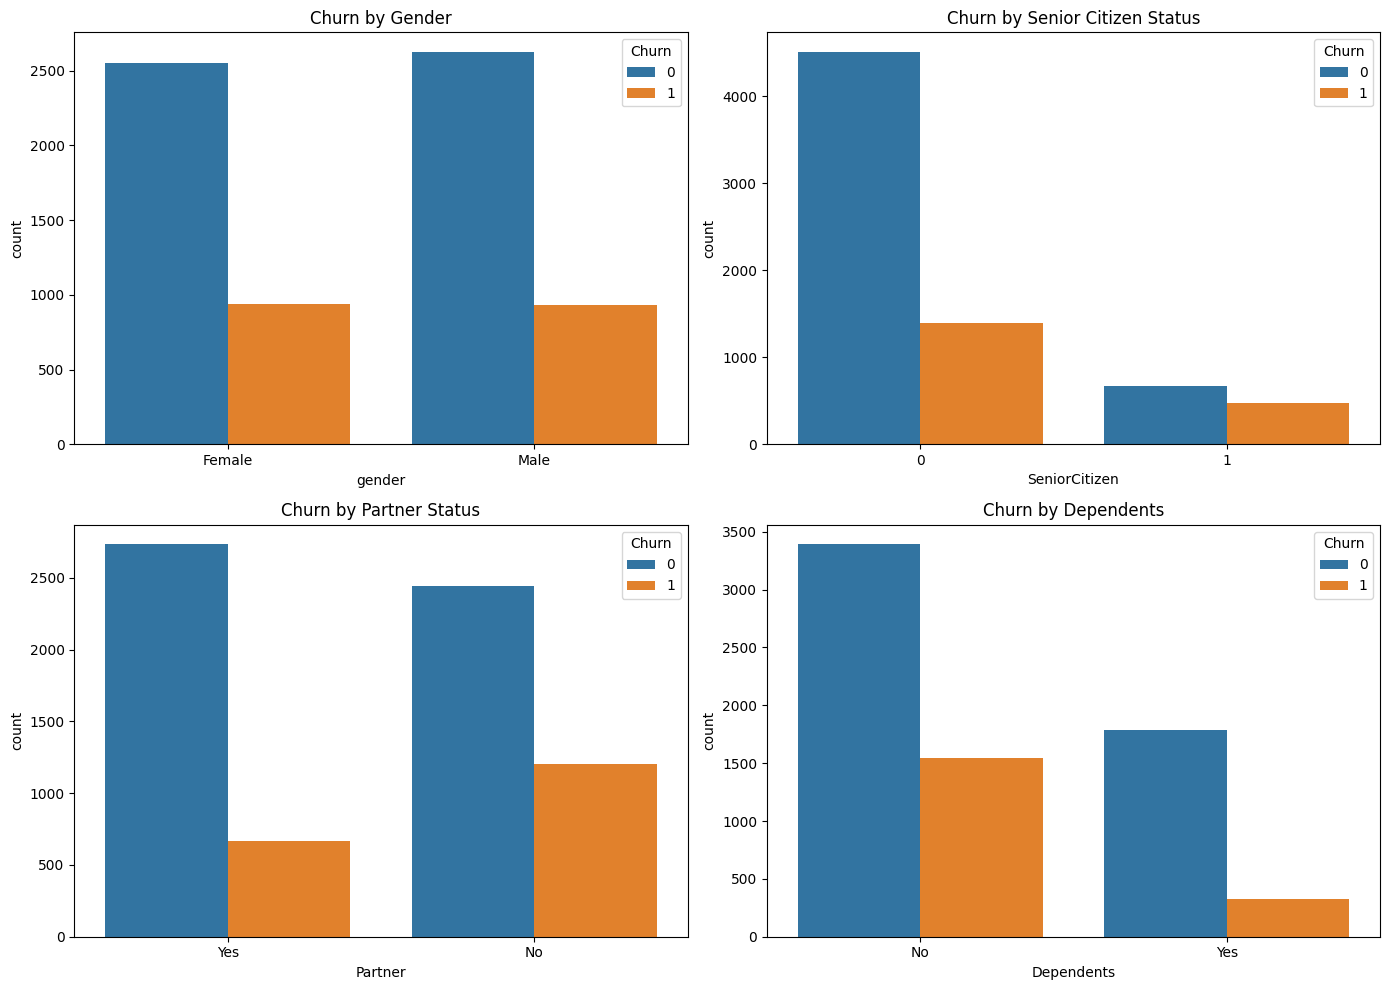

In [19]:
# seaborn making attractive and informative statistical graphics
import seaborn as sns
import matplotlib.pyplot as plt

# Set up the visualization grid
plt.figure(figsize=(14, 10))

# 1. Gender distribution against churn
plt.subplot(2, 2, 1)
sns.countplot(x='gender', hue='Churn', data=data)
plt.title('Churn by Gender')

# 2. SeniorCitizen and churn
plt.subplot(2, 2, 2)
sns.countplot(x='SeniorCitizen', hue='Churn', data=data)
plt.title('Churn by Senior Citizen Status')

# 3. Partner with churn
plt.subplot(2, 2, 3)
sns.countplot(x='Partner', hue='Churn', data=data)
plt.title('Churn by Partner Status')

# 4. Dependents with churn
plt.subplot(2, 2, 4)
sns.countplot(x='Dependents', hue='Churn', data=data)
plt.title('Churn by Dependents')

plt.tight_layout()
plt.show()

Based on the Demographic Analysis graphs above, we can observe the relationship between various attributes and customer churn. It appears that customers who churn are typically those without a partner or dependents. In terms of gender, there is no significant difference.

### Service Analysis

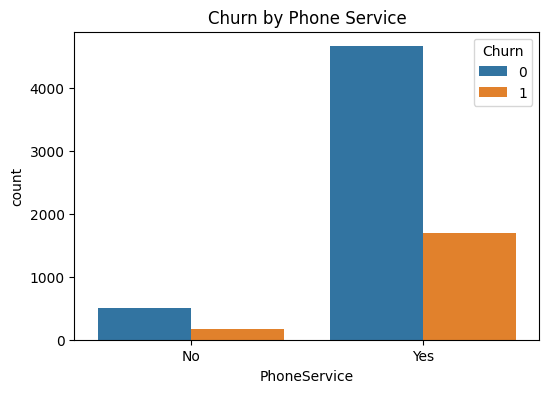

In [20]:
plt.figure(figsize=(6, 4))
sns.countplot(x='PhoneService', hue='Churn', data=data)
plt.title('Churn by Phone Service')
plt.show()

The phone service analysis above shows that over 25% of customers with phone service have churned.

### Payments Analysis

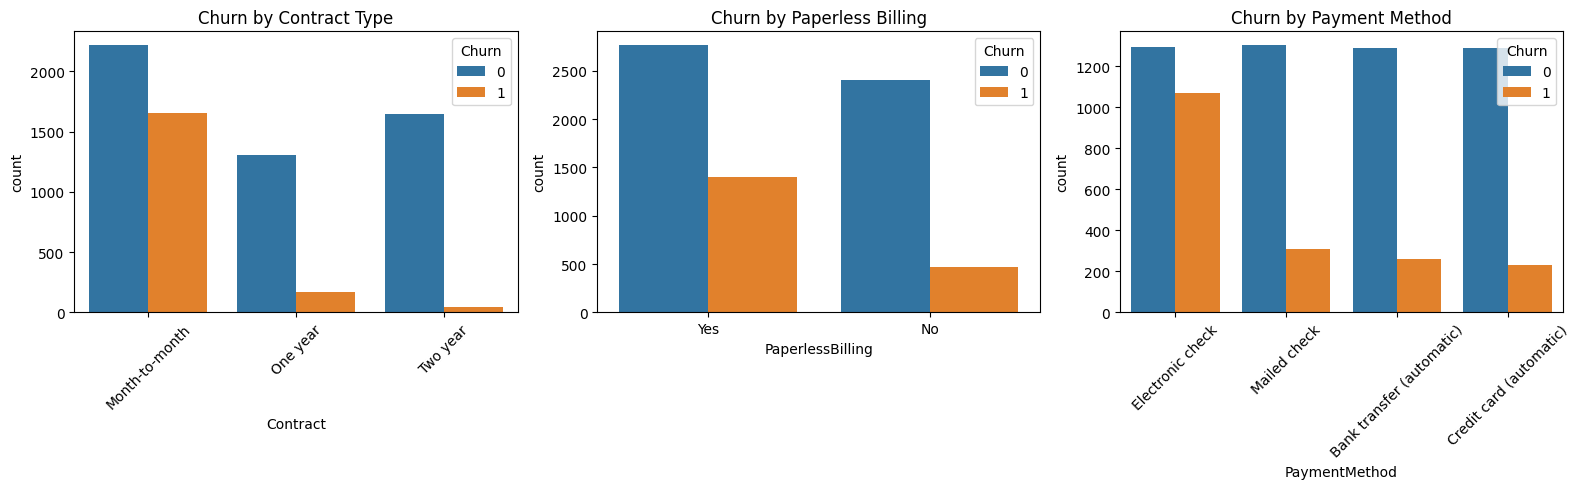

In [21]:
plt.figure(figsize=(16, 5))

# 1. Contract and churn
plt.subplot(1, 3, 1)
sns.countplot(x='Contract', hue='Churn', data=data)
plt.title('Churn by Contract Type')
plt.xticks(rotation=45)

# 2. Paperless billing and churn
plt.subplot(1, 3, 2)
sns.countplot(x='PaperlessBilling', hue='Churn', data=data)
plt.title('Churn by Paperless Billing')

# 3. Payment method and churn
plt.subplot(1, 3, 3)
sns.countplot(x='PaymentMethod', hue='Churn', data=data)
plt.title('Churn by Payment Method')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

Lastly, the graphs above explain the relationship between payment methods, contracts, and churn. We see that most people who churn are those on month-to-month contracts, use paperless billing, or pay by electronic check.